In [1]:
import numpy as np
import pandas as pd

import geopandas as gpd
from shapely.geometry import Point, Polygon
import pycno

import matplotlib.pyplot as plt

import glob

today = str(pd.Timestamp.today().date())

In [14]:
# Read in CSV and set index to unique ID
df =  pd.read_csv('Process_Rx/Brazil_cleaned_v2024-02-16.csv',low_memory=False)
# FTM_df = pd.read_csv('Process_Rx/USA/FTM.csv',low_memory=False)
# MTBS_df = pd.read_csv('Process_Rx/USA/MTBS.csv',low_memory=False)
# USGS_df = pd.read_csv('Process_Rx/USA/USGS.csv',low_memory=False)

# countries = np.unique(df['Country'])

# Add day of year column for seasonal analysis
# df['DOY'] = pd.DatetimeIndex(df['Date'].values).dayofyear

In [4]:
# Add alphabetized biome codes from ecoregion shapefile (will need for plotting biomes later)
biomes = ['Boreal Forests/Taiga','Tundra','Deserts & Xeric Shrublands',
        'Mediterranean Forests, Woodlands & Scrub','Montane Grasslands & Shrublands',
        'Flooded Grasslands & Savannas','Temperate Grasslands, Savannas & Shrublands',
        'Tropical & Subtropical Grasslands, Savannas & Shrublands',
        'Temperate Broadleaf & Mixed Forests','Tropical & Subtropical Moist Broadleaf Forests',
        'Tropical & Subtropical Dry Broadleaf Forests','Temperate Conifer Forests',
        'Tropical & Subtropical Coniferous Forests']
biomes.sort()
df['BIOME CODE'] = None
biome_codes = [6,13,9,12,10,4,5,8,3,2,7,1,11]

# Dictionary to map biomes to their biome code
biome_dict = {}
i=0
for biome in biomes:
    biome_dict[biome] = biome_codes[i]
    i+=1
biome_dict['Lake'] = 98
biome_dict['Rock/Ice'] = 99
biome_dict['Mangrove'] = 14
biome_dict_inv = dict((v, k) for k, v in biome_dict.items())

## Specify country and read in shapefiles

In [16]:
country = 'Brazil'
# country_df = df[df['Country']==country]
# region = 'Western_Australia'
# country_df = pd.read_csv('Process_Rx/USA/USGS.csv')
# country_df.drop(country_df.columns[0],axis=1)
country_df = df

world_shp = gpd.read_file(glob.glob('world_shp/*.shp')[0]).to_crs('EPSG:4326')

# Country shapefile
try:
    country_shp = gpd.read_file(glob.glob(country+'_shp/*.shp')[0]).to_crs('EPSG:4326')
except:
    # If shapefile doesn't have a pre-existing CRS
    country_shp = gpd.read_file(glob.glob(country+'_shp/*.shp')[0]).set_crs('EPSG:4326')
country_shp.set_index(country_shp.columns[0],inplace=True)
bounds = country_shp['geometry'].bounds
xlim = [bounds['minx'].min(),bounds['maxx'].max()]
ylim = [bounds['miny'].min(),bounds['maxy'].max()]

# Ecoregions shapefile
eco_shp = gpd.read_file('official_teow/wwf_terr_ecos.shp').to_crs('EPSG:4326')
eco_shp.set_index('OBJECTID',inplace=True)

# Find ecoregions only within country
country_eco_shp = gpd.sjoin(country_shp,eco_shp)

# Index of ecoregions in country in original ecoregion shapefile
eco_idx = np.unique(country_eco_shp['index_right'])

# Extract ecoregions only within country
country_eco = eco_shp.loc[eco_idx]

# Fires in each administrative boundary of country
fire_pts = gpd.GeoDataFrame({'geometry':[Point(xy) for xy in zip(country_df['Longitude'],country_df['Latitude'])]})
fire_pts.crs = 'EPSG:4326'
fire_shp = gpd.sjoin(country_shp,fire_pts)
fire_idx = np.unique(fire_shp['index_right'])

# Fires in each ecoregion (should be same length as country_df)
fire_eco_shp = gpd.sjoin(eco_shp,fire_pts)

<AxesSubplot:>

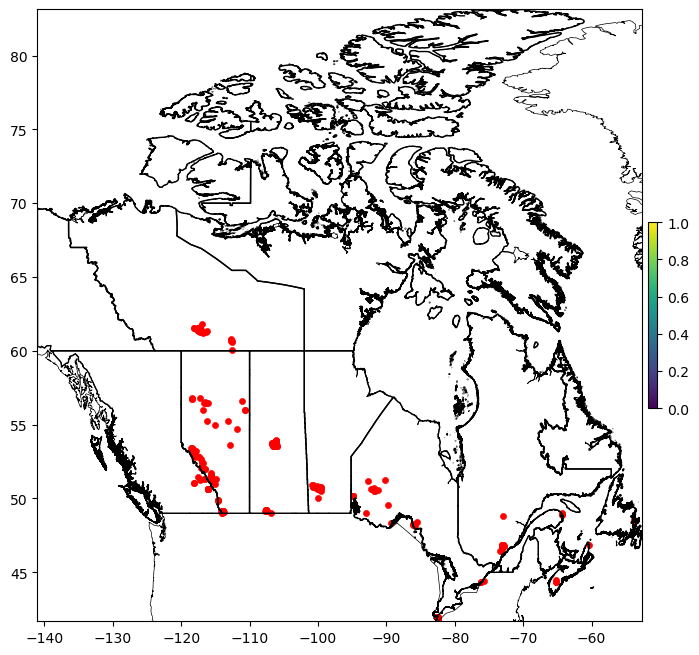

In [13]:
fig, ax = plt.subplots(figsize=(8,8))
cno = pycno.cno()
cno.draw('MWDB_Coasts_Countries_1.cnob')

lat = country_df['Latitude']
lon = country_df['Longitude']

# Color code by day of year
sc = ax.scatter(lon,lat,s=20,marker='o',color='red',linewidth=0.4)

# DOY colorbar
cbar = plt.colorbar(sc,ax=ax,fraction=0.015,pad=0.01)
    
if country=='USA':
    # Alaska
#     ax.set_xlim([-180,-140])
#     ax.set_ylim([50,71.5])
    # CONUS
    ax.set_xlim([-127,-65])
    ax.set_ylim([25,50])
elif country == 'Portugal':
    ax.set_xlim([-10,-6])
    ax.set_ylim([36.5,42.5])
elif country == 'Russia':
    ax.set_xlim([15,180])
    ax.set_ylim([40,80])
elif country == 'Japan':
    ax.set_xlim([128,146])
    ax.set_ylim([30,46])
else:
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
country_shp.plot(facecolor='none',edgecolor='black',ax=ax)

## Find values not within any of the country regions

In [17]:
err_idx = (country_df.iloc[fire_idx].index).symmetric_difference(country_df.index)

In [20]:
df.loc[err_idx]

,Unnamed: 0,Raw data filename(s),ID,Latitude,Longitude,Year,Month,Day,Time,Fire Type,Country,State/Province,Agency / Organisation,Timestamp of Update,Link to Data Repository,Citation,Area Burned,Local
6023,6093,RR_TI Raposa Serra do Sol.ods,Rx20171223-NX3.92733-WX59.07414,3.927333,-59.074139,2017.0,12.0,23.0,NaN,NaN,Brazil,Roraima;Caracaranã,IBAMA (Brazilian Institute of the Environment ...,05/05/2022,NaN,IBAMA (Brazilian Institute of the Environment ...,NaN,Caracaranã
6285,6355,RR_TI Raposa Serra do Sol.ods,Rx2018123-NX5.41778-WX60.59611,5.417778,-60.596111,2018.0,12.0,3.0,NaN,QP,Brazil,Roraima;Mangueira,IBAMA (Brazilian Institute of the Environment ...,05/05/2022,NaN,IBAMA (Brazilian Institute of the Environment ...,NaN,Mangueira
6286,6356,RR_TI Raposa Serra do Sol.ods,Rx2018123-NX5.54333-WX60.60039,5.543333,-60.600389,2018.0,12.0,3.0,NaN,QP,Brazil,Roraima;Sítio José Max,IBAMA (Brazilian Institute of the Environment ...,05/05/2022,NaN,IBAMA (Brazilian Institute of the Environment ...,NaN,Sítio José Max
6461,6531,RR_TI Raposa Serra do Sol.ods,Rx20191211-NX3.90633-WX59.44383,3.906333,-59.443833,2019.0,12.0,11.0,NaN,Fuel Reduction,Brazil,Roraima;Comunid. Monte Sião,IBAMA (Brazilian Institute of the Environment ...,05/05/2022,NaN,IBAMA (Brazilian Institute of the Environment ...,NaN,Comunid. Monte Sião
6507,6577,RR_TI Raposa Serra do Sol.ods,Rx2019129-NX3.21378-WX59.82153,3.213778,-59.821528,2019.0,12.0,9.0,NaN,Fuel Reduction,Brazil,Roraima;Normandia,IBAMA (Brazilian Institute of the Environment ...,05/05/2022,NaN,IBAMA (Brazilian Institute of the Environment ...,NaN,Normandia
6873,6943,RR_TI Raposa Serra do Sol.ods,Rx20201228-NX4.82128-WX59.76097,4.821278,-59.760972,2020.0,12.0,28.0,NaN,Fuel Reduction,Brazil,Roraima;T.I. Raposa,IBAMA (Brazilian Institute of the Environment ...,05/05/2022,NaN,IBAMA (Brazilian Institute of the Environment ...,NaN,T.I. Raposa
6979,7049,RR_TI SaÌƒo Marcos.ods,Rx20170110-NX4.93361-WX60.93822,4.933611,-60.938222,2017.0,1.0,10.0,NaN,NaN,Brazil,Roraima;Faz. São Francisco,IBAMA (Brazilian Institute of the Environment ...,05/05/2022,NaN,IBAMA (Brazilian Institute of the Environment ...,NaN,Faz. São Francisco
6980,7050,RR_TI SaÌƒo Marcos.ods,Rx20170110-NX4.93306-WX61.01211,4.933056,-61.012111,2017.0,1.0,10.0,NaN,NaN,Brazil,Roraima;Faz. São Francisco,IBAMA (Brazilian Institute of the Environment ...,05/05/2022,NaN,IBAMA (Brazilian Institute of the Environment ...,NaN,Faz. São Francisco
7014,7084,RR_TI SaÌƒo Marcos.ods,Rx20181127-NX4.18083-WX62.20861,4.180833,-62.208611,2018.0,11.0,27.0,NaN,QP,Brazil,Roraima;Maruái,IBAMA (Brazilian Institute of the Environment ...,05/05/2022,NaN,IBAMA (Brazilian Institute of the Environment ...,NaN,Maruái
7024,7094,RR_TI SaÌƒo Marcos.ods,Rx20181127-NX6.20417-WX61.26333,6.204167,-61.263333,2018.0,11.0,27.0,NaN,QP,Brazil,Roraima;São Jorge,IBAMA (Brazilian Institute of the Environment ...,05/05/2022,NaN,IBAMA (Brazilian Institute of the Environment ...,NaN,São Jorge


### USA corrections

In [80]:
# MTBS
elim_idx = err_idx

# No points for USGS or FTM

### Canada Corrections

In [71]:
elim_idx = country_df.loc[err_idx].loc[np.round(country_df['Latitude'],5)==0].loc[(np.round(country_df['Longitude'],5)==0)].index
elim_idx = elim_idx.append(country_df.loc[country_df['Latitude']<-80].index)
elim_idx = elim_idx.append(pd.Index([88,206,209]))

### Brazil Corrections

In [67]:
country_df.drop(country_df.columns[-5:-1],axis=1,inplace=True)
country_df = country_df[~np.isnan(country_df['Year'].values)]
country_df = country_df[~np.isnan(country_df['Longitude'].values)]
country_df.drop(country_df.loc[np.round(country_df['Latitude'],5)==0].loc[(np.round(country_df['Longitude'],5)==0)].index,axis=0,inplace=True)

# Drop duplicates
country_df.drop([8120,2200,3636,3553],inplace=True)

# Drop unresolvable lat/lon errors
country_df.drop([695,930,8236,5780,5782,5784,10175,1747,197,
                 355,7432,10136,5073,717,952,2314,8884,9322,
                 10774,11054,5781,5783,5785,5786,5787],inplace=True)

# Corrections
country_df.loc[3439,'Longitude'] = country_df.loc[3439,'Longitude']/10
country_df.loc[7748,'Longitude'] = country_df.loc[7748,'Longitude']/100
country_df.loc[8306,'Longitude'] = country_df.loc[8306,'Longitude']/10
country_df.loc[2397,'Longitude'] = -53.418194
country_df.loc[10986,'Latitude'] = -11.893333
country_df.loc[94,'Longitude'] = -country_df.loc[94,'Longitude']
country_df.loc[394,'Longitude'] = -country_df.loc[394,'Longitude']
country_df.loc[5978,'Latitude'] = 3.580083

# Keep Roraima datapoints in dataset; remove from error index
rma_idx = [5978, 6093, 6355, 6356, 6531, 6577, 6943, 7049, 7050, 7084, 7094,
            7095, 7096, 7097, 7117, 7118, 7127, 7129, 7130, 7132, 7133, 7135,
            7147, 7151, 7167, 7168, 7169, 7170, 7171, 7172, 7173, 7174, 7175,
            7176]
err_idx = [idx for idx in err_idx if idx not in rma_idx]

In [184]:
rma_idx = [5978, 6093, 6355, 6356, 6531, 6577, 6943, 7049, 7050, 7084, 7094,
            7095, 7096, 7097, 7117, 7118, 7127, 7129, 7130, 7132, 7133, 7135,
            7147, 7151, 7167, 7168, 7169, 7170, 7171, 7172, 7173, 7174, 7175,
            7176]
err_idx = [idx for idx in err_idx if idx not in rma_idx]
country_df.loc[err_idx]

,Raw data filename(s),ID,Latitude,Longitude,Year,Month,Day,Time,Fire Type,Country,State/Province,Agency / Organisation,Timestamp of Update,Link to Data Repository,Citation,Area Burned,Local


In [30]:
# # All points with lat, lon = (0,0); all points labelled as Mato Grosso with lat < -20
# elim_idx = country_df.loc[err_idx].loc[np.round(country_df['Latitude'],5)==0].loc[(np.round(country_df['Longitude'],5)==0)].index

# elim_idx = elim_idx.append([country_df.loc[err_idx].loc[country_df['Latitude']<-20].loc[country_df['State/Province']=='Mato Grosso'].index])
# elim_idx = elim_idx.append(country_df.loc[err_idx.symmetric_difference(elim_idx)].loc[country_df['Longitude']>-20].index)
# # elim_idx = elim_idx.append(country_df.loc[[122325, 127307, 127740, 129173, 129450, 128582]].index)

# country_df.drop(elim_idx,axis=0,inplace=True)

# country_df['Notes'] = None

# # Correct the coordinates on:
# country_df.loc[124513,'Notes'] = 'Original latitude divided by 10'
# country_df.loc[124513,'Latitude'] = country_df.loc[124513,'Latitude']/10

# country_df.loc[125959,'Notes'] = '0 added to original latitude (-6.72... to -60.72...). -61.72... possible also'
# country_df.loc[125959,'Longitude'] = -60.721194

# country_df.loc[120888,'Notes'] = 'Original longitude multiplied by -1'
# country_df.loc[120888,'Longitude'] = -country_df.loc[120888,'Longitude']

# country_df.loc[121356,'Notes'] = 'Original latitude multiplied by -1 and divided by 10. Coincides with Krikati territory.'
# country_df.loc[121356,'Latitude'] = -country_df.loc[121356,'Latitude']/10

<AxesSubplot:>

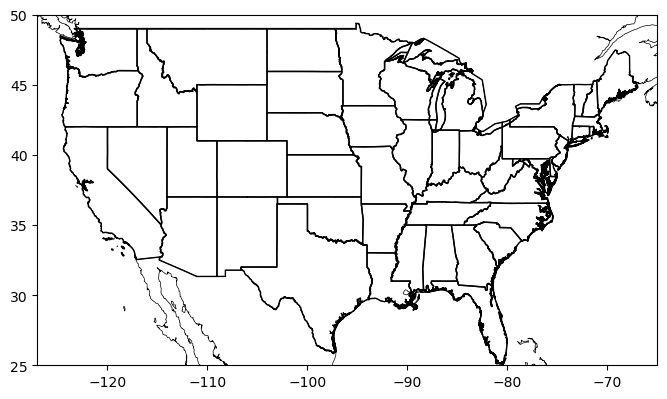

In [7]:
fig, ax = plt.subplots(figsize=(8,8))
cno = pycno.cno()
cno.draw('MWDB_Coasts_Countries_1.cnob')

lat = country_df['Latitude'].loc[err_idx]
lon = country_df['Longitude'].loc[err_idx]

sc = ax.scatter(lon,lat,s=10,marker='.',color='red')

if country=='USA':
    # Alaska
#     ax.set_xlim([-180,-140])
#     ax.set_ylim([50,71.5])
    # CONUS
    ax.set_xlim([-127,-65])
    ax.set_ylim([25,50])
elif country == 'Portugal':
    ax.set_xlim([-10,-6])
    ax.set_ylim([36.5,42.5])
elif country == 'Russia':
    ax.set_xlim([15,180])
    ax.set_ylim([40,80])
elif country == 'Japan':
    ax.set_xlim([128,146])
    ax.set_ylim([30,46])
else:
#     ax.set_xlim([142,145])
#     ax.set_ylim([-15,-14])
#     xlim = [np.min(lon),np.max(lon)]
#     ylim = [np.min(lat),np.max(lat)]
    xlim = [bounds['minx'].min(),bounds['maxx'].max()]
    ylim = [bounds['miny'].min(),bounds['maxy'].max()]
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    
country_shp.plot(facecolor='none',edgecolor='black',ax=ax)

<AxesSubplot:>

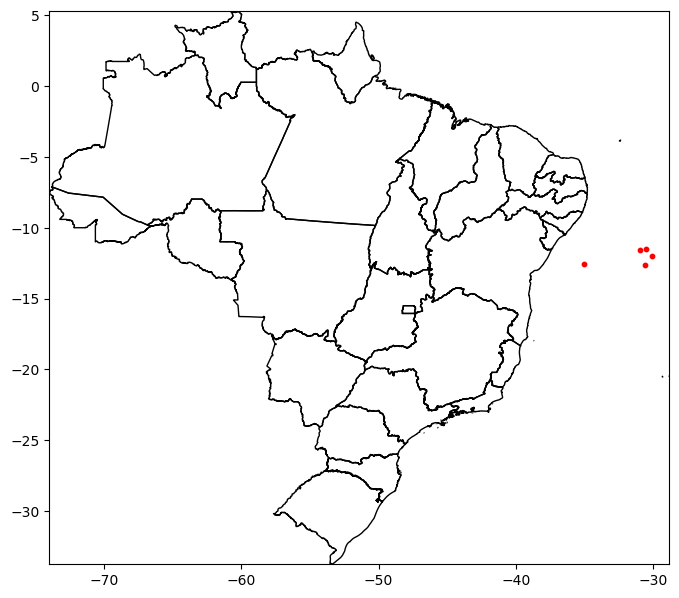

In [171]:
idx = [273,277,282,290,319,343,383,388]
# country_df.loc[err_idx].loc[country_df['State/Province']=='Florida'].index
# idx = elim_idx

fig, ax = plt.subplots(figsize=(8,8))
# cno = pycno.cno()
# cno.draw('MWDB_Coasts_Countries_1.cnob')

lat = country_df['Latitude'][idx]
lon = country_df['Longitude'][idx]

sc = ax.scatter(lon,lat,s=10,marker='o',color='red')

xlim = [bounds['minx'].min(),bounds['maxx'].max()]
ylim = [bounds['miny'].min(),bounds['maxy'].max()]
# ax.set_xlim([-76,-75.7])
# ax.set_ylim([35.5,35.8])
# xlim = [np.min(lon),np.max(lon)]
# ylim = [np.min(lat),np.max(lat)]
ax.set_xlim(xlim)
ax.set_ylim(ylim)
country_shp.plot(facecolor='none',edgecolor='black',ax=ax)

## Remove datapoints from reference data

### Australia

In [249]:
elim_idx = country_df.loc[err_idx].index

filename = glob.glob('Process_Rx/'+country+'/'+region+'*.csv')[0]
reg_df = pd.read_csv(filename)
reg_df.drop(reg_df.columns[0],axis=1,inplace=True)

clean_df = reg_df.drop(elim_idx,axis=0)
clean_df.to_csv('Process_Rx/'+country+'/'+region+'_cleaned_v'+today+'.csv')

elim_reg_df = reg_df.loc[elim_idx]
elim_reg_df.to_csv('Process_Rx/'+country+'/'+region+'_deleted_points_v'+today+'.csv')

### USA

In [63]:
country_df.loc[elim_idx].to_csv('Process_Rx/USA/MTBS_deleted_points_v'+today+'.csv')
country_df.drop(elim_idx,inplace=True)
country_df.to_csv('Process_Rx/USA/MTBS_cleaned_v'+today+'.csv')

### Brazil

In [204]:
country_df.to_csv('Process_Rx/'+country+'_cleaned_v'+today+'.csv')

In [201]:
(country_df["State/Province"].astype(str)+';'+country_df["Local"].astype(str)).values

array(['Amazonas;Igarapé Preto', 'Amazonas;Igarapé Preto',
       'Amazonas;Igarapé Preto', ..., 'Tocantins;Cercadinho',
       'Tocantins;Serrinha', 'Tocantins;Rio sono'], dtype=object)

In [203]:
country_df['State/Province']

0        Amazonas;Igarapé Preto
1        Amazonas;Igarapé Preto
2        Amazonas;Igarapé Preto
3        Amazonas;Igarapé Preto
4            Goiás;Entorno PNCV
                  ...          
12344           Tocantins;Ktepo
12345          Tocantins;Boa fé
12346      Tocantins;Cercadinho
12347        Tocantins;Serrinha
12348        Tocantins;Rio sono
Name: State/Province, Length: 12246, dtype: object

### Canada

In [73]:
country_df.loc[elim_idx].to_csv('Process_Rx/Canada/NFDB_deleted_points_v'+today+'.csv')
country_df.drop(elim_idx,inplace=True)
country_df.to_csv('Process_Rx/Canada/NFDB_cleaned_v'+today+'.csv')

<AxesSubplot:>

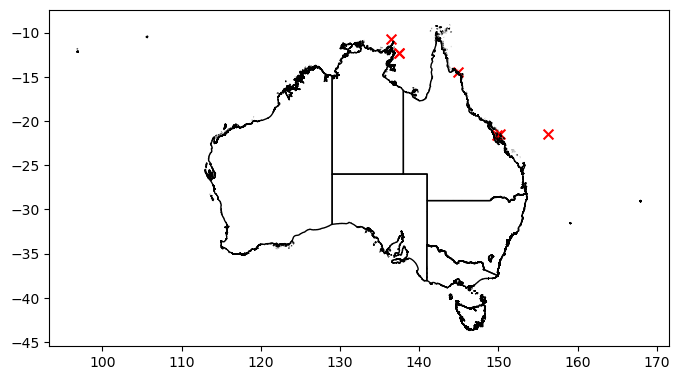

In [195]:
fig, ax = plt.subplots(figsize=(8,8))
# cno = pycno.cno()
# cno.draw('MWDB_Coasts_Countries_1.cnob')

lat = reg_df.loc[elim_reg_idx,'Latitude']
lon = reg_df.loc[elim_reg_idx,'Longitude']

sc = ax.scatter(lon,lat,s=50,marker='x',color='red')

# xlim = [bounds['minx'].min(),bounds['maxx'].max()]
# ylim = [bounds['miny'].min(),bounds['maxy'].max()]
# ax.set_xlim([-69,-68])
# ax.set_ylim([44,44.5])
# xlim = [np.min(lon),np.max(lon)]
# ylim = [np.min(lat),np.max(lat)]
# ax.set_xlim(xlim)
# ax.set_ylim(ylim)
country_shp.plot(facecolor='none',edgecolor='black',ax=ax)